In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Python executable:", sys.executable)
print("Pandas version:", pd.__version__)

Python executable: /workspaces/dairy-cow-mastitis-detection/.venv/bin/python
Pandas version: 3.1.1


In [12]:
from pathlib import Path

data_path = Path("data/clinical_mastitis_cows.csv")
df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("Unique cow IDs:", df["Cow_ID"].nunique())
display(df.head())

Dataset shape: (6600, 18)
Unique cow IDs: 1100


,Cow_ID,Day,Breed,Months after giving birth,Previous_Mastits_status,IUFL,EUFL,IUFR,EUFR,IURL,EURL,IURR,EURR,Temperature,Hardness,Pain,Milk_visibility,class1
0,cow1,1,Jersey,1,0,150,180,150,180,150,181,150,181,43,0,0,0,0
1,cow1,2,Jersey,1,0,152,180,152,185,151,180,152,181,42,0,0,0,0
2,cow1,3,Jersey,1,0,152,182,153,186,151,186,153,183,41,0,0,0,0
3,cow1,4,Jersey,1,0,155,183,155,189,155,182,155,186,40,0,0,0,0
4,cow1,5,Jersey,1,0,150,186,150,181,150,185,150,188,41,0,0,0,0


In [3]:
print("Column types and missing values:")
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique_values": df.nunique(),
}))

print("Exact duplicate rows:", df.duplicated().sum())

print("\nRepeated cow/day combinations:")
print(df.duplicated(subset=["Cow_ID", "Day"]).sum())

print("\nTarget counts (0 = normal, 1 = mastitis):")
display(df["class1"].value_counts().sort_index())

print("\nRecords per cow:")
display(df.groupby("Cow_ID").size().value_counts().sort_index())

print("\nNumerical ranges:")
display(df.describe().T)

Column types and missing values:


,dtype,missing,unique_values
Cow_ID,str,0,1100
Day,int64,0,6
Breed,str,0,2
Months after giving birth,int64,0,6
Previous_Mastits_status,int64,0,2
IUFL,int64,0,142
EUFL,int64,0,147
IUFR,int64,0,145
EUFR,int64,0,143
IURL,int64,0,144


Exact duplicate rows: 0

Repeated cow/day combinations:
0

Target counts (0 = normal, 1 = mastitis):


class1
0    3961
1    2639
Name: count, dtype: int64


Records per cow:


6    1100
Name: count, dtype: int64


Numerical ranges:


,count,mean,std,min,25%,50%,75%,max
Day,6600.0,3.500000,1.707955,1.0,2.0,3.5,5.00,6.0
Months after giving birth,6600.0,3.326818,1.691284,1.0,2.0,3.0,5.00,6.0
Previous_Mastits_status,6600.0,0.003636,0.060197,0.0,0.0,0.0,0.00,1.0
IUFL,6600.0,217.476667,49.932071,130.0,159.0,233.0,241.00,322.0
EUFL,6600.0,251.981515,57.665726,152.0,187.0,273.0,279.25,372.0
IUFR,6600.0,215.006061,47.432513,130.0,159.0,233.0,240.00,343.0
EUFR,6600.0,250.643333,55.220566,151.0,187.0,273.0,280.00,393.0
IURL,6600.0,213.584394,50.001508,130.0,158.0,233.0,240.00,327.0
EURL,6600.0,249.082273,58.478084,152.0,185.0,273.0,280.00,372.0
IURR,6600.0,206.594394,40.659276,121.0,158.0,233.0,238.00,315.0


In [4]:
from sklearn.model_selection import GroupShuffleSplit

# Keep the original df and CSV unchanged.
df_clean = df.copy()
df_clean.columns = (
    df_clean.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

df_clean = df_clean.rename(columns={
    "class1": "mastitis",
    "previous_mastits_status": "previous_mastitis_status",
})

# Hold out 20% of cows for final testing.
split_test = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=42
)

train_val_idx, test_idx = next(
    split_test.split(df_clean, groups=df_clean["cow_id"])
)

df_full_train = df_clean.iloc[train_val_idx].copy()
df_test = df_clean.iloc[test_idx].copy()

# Hold out 25% of the remaining cows for validation.
split_val = GroupShuffleSplit(
    n_splits=1, test_size=0.25, random_state=42
)

train_idx, val_idx = next(
    split_val.split(
        df_full_train,
        groups=df_full_train["cow_id"],
    )
)

df_train = df_full_train.iloc[train_idx].copy()
df_val = df_full_train.iloc[val_idx].copy()

# Verify that cow IDs do not overlap.
train_cows = set(df_train["cow_id"])
val_cows = set(df_val["cow_id"])
test_cows = set(df_test["cow_id"])

assert train_cows.isdisjoint(val_cows)
assert train_cows.isdisjoint(test_cows)
assert val_cows.isdisjoint(test_cows)

summary = pd.DataFrame([
    {
        "split": name,
        "rows": len(part),
        "cows": part["cow_id"].nunique(),
        "mastitis_fraction": part["mastitis"].mean(),
    }
    for name, part in [
        ("train", df_train),
        ("validation", df_val),
        ("test", df_test),
    ]
])

display(summary)
print("Verified: no cow appears in more than one split.")

,split,rows,cows,mastitis_fraction
0,train,3960,660,0.396717
1,validation,1320,220,0.381818
2,test,1320,220,0.427273


Verified: no cow appears in more than one split.


Training-set sensor medians by mastitis status:


mastitis,normal,mastitis
iufl,230.0,239.0
eufl,268.0,278.0
iufr,230.0,238.0
eufr,270.0,280.0
iurl,230.0,237.0
eurl,268.0,278.0
iurr,230.0,235.0
eurr,269.0,275.0
temperature,43.0,43.0


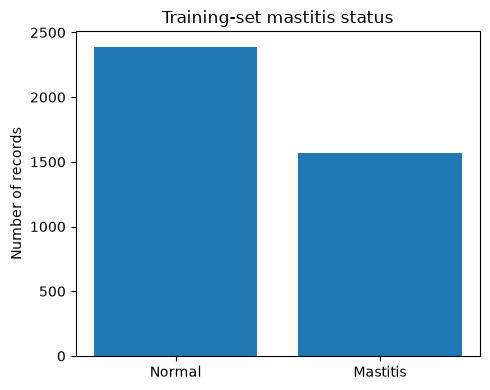

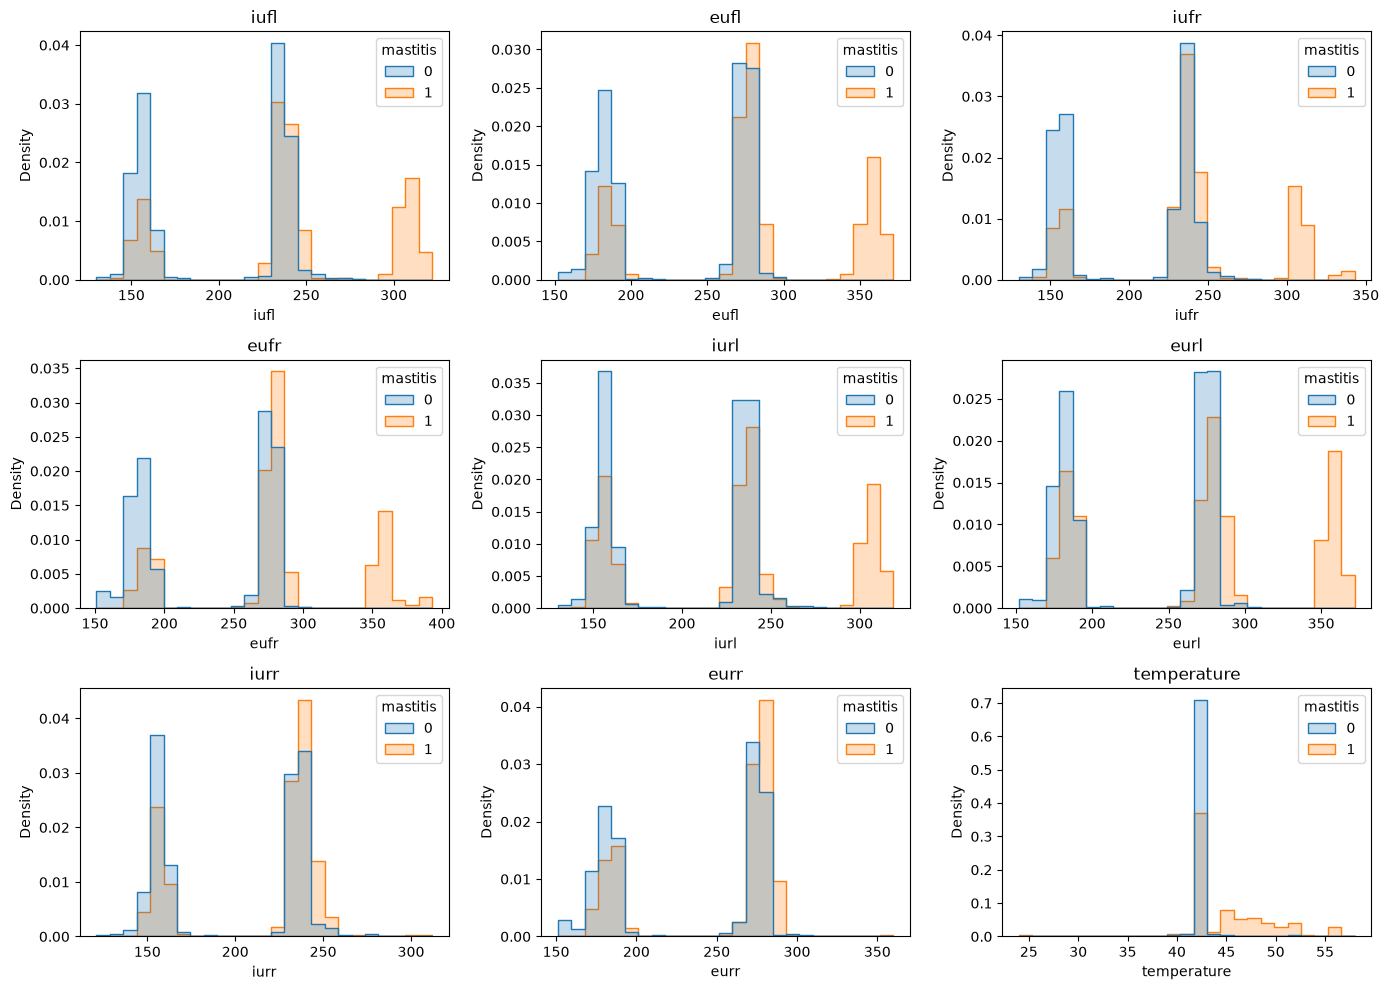

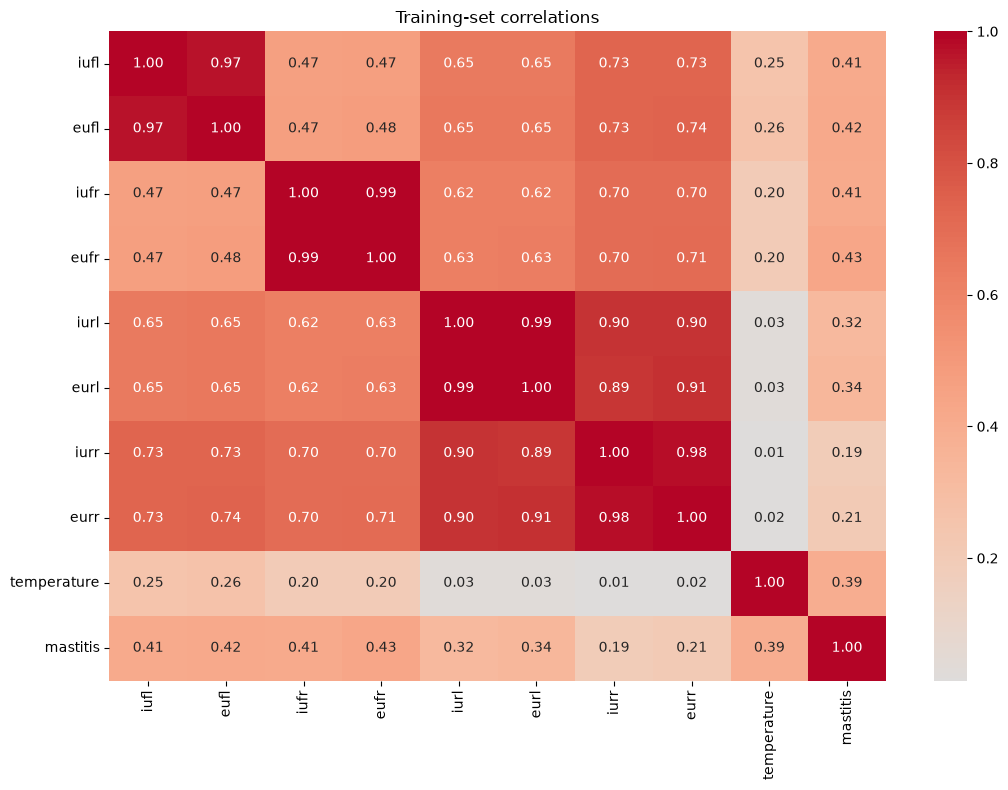

In [5]:
sensor_features = [
    "iufl", "eufl",
    "iufr", "eufr",
    "iurl", "eurl",
    "iurr", "eurr",
    "temperature",
]

# Summarise sensor values within each target class.
print("Training-set sensor medians by mastitis status:")
display(
    df_train.groupby("mastitis")[sensor_features]
    .median()
    .T
    .rename(columns={0: "normal", 1: "mastitis"})
)

# Target distribution.
counts = df_train["mastitis"].value_counts().reindex([0, 1])

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Normal", "Mastitis"], counts.values)
ax.set_ylabel("Number of records")
ax.set_title("Training-set mastitis status")
plt.tight_layout()
plt.show()

# Compare sensor distributions between classes.
fig, axes = plt.subplots(3, 3, figsize=(14, 10))

for feature, ax in zip(sensor_features, axes.flat):
    sns.histplot(
        data=df_train,
        x=feature,
        hue="mastitis",
        bins=25,
        stat="density",
        common_norm=False,
        element="step",
        ax=ax,
    )
    ax.set_title(feature)

plt.tight_layout()
plt.show()

# Correlations among sensors and with the target.
plt.figure(figsize=(11, 8))
sns.heatmap(
    df_train[sensor_features + ["mastitis"]].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)
plt.title("Training-set correlations")
plt.tight_layout()
plt.show()

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)
from xgboost import XGBClassifier

X_train = df_train[sensor_features]
y_train = df_train["mastitis"]

X_val = df_val[sensor_features]
y_val = df_val["mastitis"]

models = {
    "Dummy baseline": DummyClassifier(strategy="prior"),

    "Logistic regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42),
    ),

    "Random forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=2,
    ),
}

baseline_results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_val)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    baseline_results.append({
        "model": name,
        "roc_auc": roc_auc_score(y_val, probabilities),
        "average_precision": average_precision_score(
            y_val, probabilities
        ),
        "accuracy": accuracy_score(y_val, predictions),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(y_val, predictions, zero_division=0),
    })

results_baseline = pd.DataFrame(baseline_results)
display(
    results_baseline
    .sort_values("roc_auc", ascending=False)
    .round(4)
)

,model,roc_auc,average_precision,accuracy,precision,recall,f1
2,Random forest,0.9764,0.9691,0.9182,0.9439,0.8353,0.8863
3,XGBoost,0.9696,0.9614,0.9129,0.9576,0.8075,0.8762
1,Logistic regression,0.9036,0.9049,0.8780,0.9858,0.6905,0.8121
0,Dummy baseline,0.5000,0.3818,0.6182,0.0000,0.0000,0.0000


In [7]:
from sklearn.model_selection import GroupKFold, GridSearchCV

parameter_grid = {
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 5, 10],
}

cv = GroupKFold(n_splits=3)

rf_search = GridSearchCV(
    estimator=RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1,
    ),
    param_grid=parameter_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=2,
    return_train_score=True,
)

rf_search.fit(
    X_train,
    y_train,
    groups=df_train["cow_id"],
)

tuning_results = pd.DataFrame(rf_search.cv_results_)

display(
    tuning_results[[
        "param_max_depth",
        "param_min_samples_leaf",
        "mean_train_score",
        "mean_test_score",
        "std_test_score",
    ]]
    .sort_values("mean_test_score", ascending=False)
    .round(4)
)

print("Best parameters:", rf_search.best_params_)
print("Best mean CV ROC AUC:", round(rf_search.best_score_, 4))

best_rf = rf_search.best_estimator_
val_probabilities_rf = best_rf.predict_proba(X_val)[:, 1]

print(
    "Tuned validation ROC AUC:",
    round(roc_auc_score(y_val, val_probabilities_rf), 4),
)

,param_max_depth,param_min_samples_leaf,mean_train_score,mean_test_score,std_test_score
6,None,1,1.0000,0.9955,0.0018
7,None,5,0.9993,0.9925,0.0026
8,None,10,0.9966,0.9899,0.0034
3,10,1,0.9962,0.9873,0.0038
4,10,5,0.9948,0.9868,0.0040
5,10,10,0.9929,0.9851,0.0042
1,5,5,0.9726,0.9647,0.0058
0,5,1,0.9733,0.9646,0.0050
2,5,10,0.9706,0.9637,0.0067


Best parameters: {'max_depth': None, 'min_samples_leaf': 1}
Best mean CV ROC AUC: 0.9955
Tuned validation ROC AUC: 0.9851


Validation results at threshold 0.5
Correct normal predictions: 794
False alerts: 22
Missed mastitis records: 24
Correct mastitis predictions: 480
Precision: 0.9562
Recall: 0.9524
F1: 0.9543


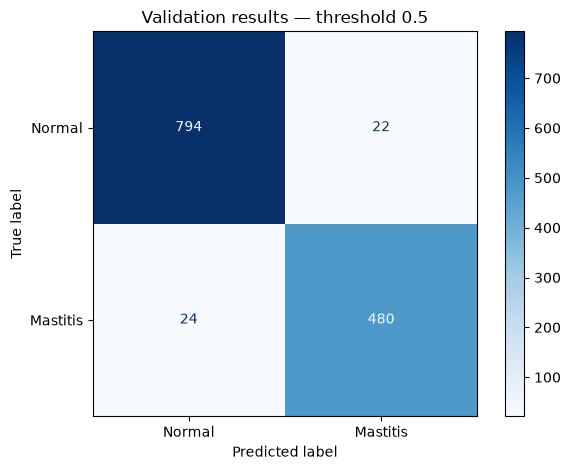

,feature,mean_auc_decrease,std
0,iufl,0.0563,0.0044
5,eurl,0.0450,0.0036
3,eufr,0.0431,0.0042
4,iurl,0.0283,0.0039
2,iufr,0.0198,0.0025
1,eufl,0.0099,0.0019
7,eurr,0.0056,0.0014
8,temperature,0.0046,0.0014
6,iurr,0.0009,0.0006


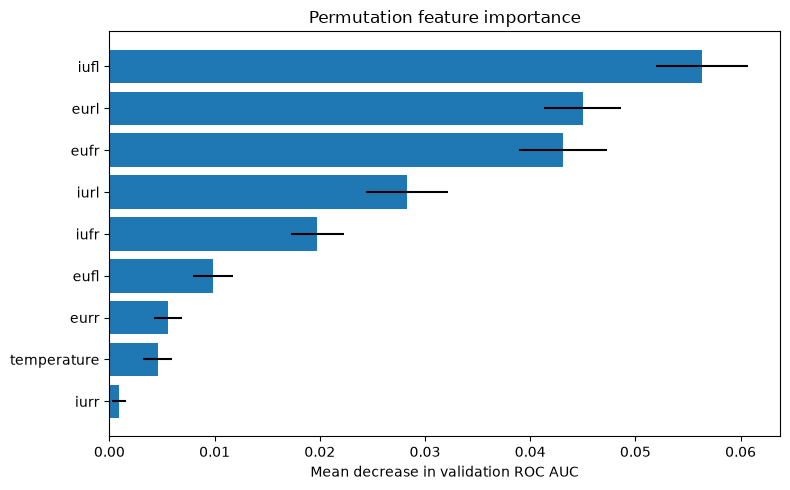

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

# Evaluate the current threshold of 0.5.
val_predictions_rf = (val_probabilities_rf >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_val, val_predictions_rf, labels=[0, 1]
).ravel()

print("Validation results at threshold 0.5")
print("Correct normal predictions:", tn)
print("False alerts:", fp)
print("Missed mastitis records:", fn)
print("Correct mastitis predictions:", tp)

print(
    "Precision:",
    round(precision_score(y_val, val_predictions_rf), 4),
)
print(
    "Recall:",
    round(recall_score(y_val, val_predictions_rf), 4),
)
print(
    "F1:",
    round(f1_score(y_val, val_predictions_rf), 4),
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_predictions_rf,
    display_labels=["Normal", "Mastitis"],
    cmap="Blues",
)
plt.title("Validation results — threshold 0.5")
plt.tight_layout()
plt.show()

# Measure the AUC decrease when each feature is shuffled.
permutation = permutation_importance(
    best_rf,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=2,
)

importance = pd.DataFrame({
    "feature": sensor_features,
    "mean_auc_decrease": permutation.importances_mean,
    "std": permutation.importances_std,
}).sort_values("mean_auc_decrease", ascending=False)

display(importance.round(4))

plt.figure(figsize=(8, 5))
plt.barh(
    importance["feature"],
    importance["mean_auc_decrease"],
    xerr=importance["std"],
)
plt.gca().invert_yaxis()
plt.xlabel("Mean decrease in validation ROC AUC")
plt.title("Permutation feature importance")
plt.tight_layout()
plt.show()

In [9]:
threshold_results = []

for threshold in [0.2, 0.3, 0.4, 0.5, 0.6]:
    predictions = (
        val_probabilities_rf >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "false_alerts": fp,
        "missed_mastitis": fn,
    })

threshold_table = pd.DataFrame(threshold_results)
display(threshold_table.round(4))

,threshold,precision,recall,f1,false_alerts,missed_mastitis
0,0.2,0.8554,0.9623,0.9057,82,19
1,0.3,0.9082,0.9623,0.9345,49,19
2,0.4,0.9324,0.9583,0.9452,35,21
3,0.5,0.9562,0.9524,0.9543,22,24
4,0.6,0.9711,0.9325,0.9514,14,34


In [10]:
selected_threshold = 0.5

print("Selected model: tuned random forest")
print("Selected threshold:", selected_threshold)
print("Selection rule: highest validation F1 among tested thresholds")

display(importance.round(4))

Selected model: tuned random forest
Selected threshold: 0.5
Selection rule: highest validation F1 among tested thresholds


,feature,mean_auc_decrease,std
0,iufl,0.0563,0.0044
5,eurl,0.0450,0.0036
3,eufr,0.0431,0.0042
4,iurl,0.0283,0.0039
2,iufr,0.0198,0.0025
1,eufl,0.0099,0.0019
7,eurr,0.0056,0.0014
8,temperature,0.0046,0.0014
6,iurr,0.0009,0.0006


,test_score
roc_auc,0.9985
average_precision,0.9978
accuracy,0.9848
precision,0.9772
recall,0.9876
f1,0.9824
specificity,0.9828


Test records: 1320
Test cows: 220
False alerts: 13
Missed mastitis records: 7


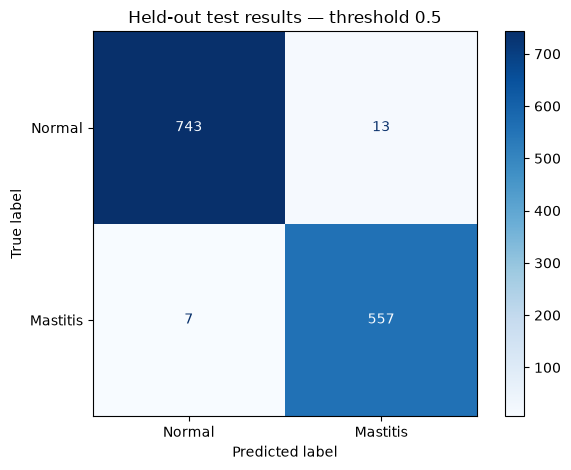

In [11]:
from sklearn.base import clone

# Refit the selected model using all development data.
final_model = clone(best_rf)

final_model.fit(
    df_full_train[sensor_features],
    df_full_train["mastitis"],
)

# Evaluate the fixed model and threshold on the held-out test set.
X_test = df_test[sensor_features]
y_test = df_test["mastitis"]

test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, test_predictions, labels=[0, 1]
).ravel()

test_metrics = {
    "roc_auc": roc_auc_score(y_test, test_probabilities),
    "average_precision": average_precision_score(
        y_test, test_probabilities
    ),
    "accuracy": accuracy_score(y_test, test_predictions),
    "precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "f1": f1_score(y_test, test_predictions, zero_division=0),
    "specificity": tn / (tn + fp),
}

display(
    pd.Series(test_metrics, name="test_score")
    .round(4)
    .to_frame()
)

print("Test records:", len(y_test))
print("Test cows:", df_test["cow_id"].nunique())
print("False alerts:", fp)
print("Missed mastitis records:", fn)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Normal", "Mastitis"],
    cmap="Blues",
)
plt.title("Held-out test results — threshold 0.5")
plt.tight_layout()
plt.show()